# 01 Manual EDA – German Credit Dataset

## Master’s Dissertation Research Pipeline

This notebook performs the first stage of the German Credit dataset pipeline: **manual exploratory data analysis (EDA)**.

The purpose is to understand the raw data before preprocessing, modelling, explainability analysis, counterfactual analysis, and the Explainability–Ethics Scoring (EES) Framework.

This notebook is designed to be reusable across the three dissertation datasets:

- German Credit
- Recidivism / COMPAS
- Diabetes

For this notebook, the dataset focus is **German Credit**.

## 1. Dissertation Alignment

The original proposal focused on responsible machine learning, interpretability, and ethical decision-making in high-stakes domains.

This EDA notebook supports that proposal by establishing a transparent understanding of the dataset before any modelling is performed. This is important because model explainability and ethical assessment are only defensible when the underlying data has been properly inspected.

The strengthened dissertation pipeline improves the proposal by making the work more reproducible, auditable, and easier to extend across multiple domains.

This remains appropriate for a **Master’s dissertation** because the contribution is an applied, reproducible, and empirically testable responsible AI framework, rather than a purely theoretical PhD-level contribution.

## 2. Objectives of this Notebook

This notebook aims to:

1. Load the German Credit dataset.
2. Combine the Kaggle feature file with the UCI target variable where required.
3. Inspect dataset structure, columns, and data types.
4. Check duplicates, missing values, and unique values.
5. Analyse the target variable distribution.
6. Separate numeric and categorical variables.
7. Inspect numeric distributions and outliers.
8. Inspect categorical feature distributions and rare categories.
9. Explore simple feature-target relationships.
10. Identify sensitive and potentially sensitive attributes.
11. Produce a feature audit table to support preprocessing decisions.
12. Save all EDA outputs into a standard results folder.

## 3. Key Assumptions

The following assumptions are applied in this notebook:

1. The German Credit features are stored in Google Drive under:

   `03_Data/01_Raw_Data/german_credit/german_credit_data.csv`

2. If the raw Kaggle file does not contain the target column, the target is retrieved from the UCI ML repository using `ucimlrepo`.

3. The UCI German Credit target is mapped as follows:

   - `1 → 1`, interpreted as good / favourable credit risk.
   - `2 → 0`, interpreted as bad / unfavourable credit risk.

4. No preprocessing decisions are applied in this notebook. EDA only informs the next notebook:

   `02_data_preprocessing_german_credit.ipynb`

5. Outliers are inspected but not automatically removed. This is important because in credit-risk datasets, extreme values may represent meaningful financial behaviour.

6. Sensitive attributes are not removed at this stage. They are documented so that later fairness, ethics, and regulatory-alignment analysis can be performed transparently.

In [4]:
# =========================================================
# 4. Project Setup and Path Configuration
# =========================================================

from pathlib import Path
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# Google Colab mount
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print("Google Drive mount skipped. This usually means the notebook is not running in Colab.")
    print(f"Details: {e}")

# Master research root
ROOT_PATH = Path("/content/drive/MyDrive/Master_Research")

# Dataset and notebook identifiers
DATASET_NAME = "german_credit"
NOTEBOOK_NAME = "01_manual_eda_german_credit"

# Input paths
RAW_DATA_PATH = ROOT_PATH / "04_Data" / "01_Raw_Data" / DATASET_NAME / "german_credit_data.csv"

# Output paths
RESULTS_PATH = ROOT_PATH / "07_Results" / DATASET_NAME / NOTEBOOK_NAME
TABLES_PATH = RESULTS_PATH / "tables"
FIGURES_PATH = RESULTS_PATH / "figures"
LOGS_PATH = RESULTS_PATH / "logs"
DATASETS_PATH = RESULTS_PATH / "datasets"

# Create folders
for path in [RESULTS_PATH, TABLES_PATH, FIGURES_PATH, LOGS_PATH, DATASETS_PATH]:
    path.mkdir(parents=True, exist_ok=True)

print("Project setup complete.")
print(f"Root path: {ROOT_PATH}")
print(f"Raw data path: {RAW_DATA_PATH}")
print(f"Results path: {RESULTS_PATH}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project setup complete.
Root path: /content/drive/MyDrive/Master_Research
Raw data path: /content/drive/MyDrive/Master_Research/04_Data/01_Raw_Data/german_credit/german_credit_data.csv
Results path: /content/drive/MyDrive/Master_Research/07_Results/german_credit/01_manual_eda_german_credit


## 5. Load Dataset

This section loads the German Credit features file. If the `class` column is already present, it will be used directly. If the target column is missing, the notebook retrieves the target variable from the UCI ML repository.

In [5]:
# =========================================================
# 5. Load German Credit Dataset
# =========================================================

if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Raw data file not found at: {RAW_DATA_PATH}\n"
        "Please confirm that german_credit_data.csv is saved in the expected Google Drive folder."
    )

df = pd.read_csv(RAW_DATA_PATH)

print("Feature dataset loaded successfully.")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
display(df.head())

Feature dataset loaded successfully.
Rows: 1000
Columns: 10


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,0,67,male,2,own,NaN,little,1169,6,radio/TV
1,1,22,female,2,own,little,moderate,5951,48,radio/TV
2,2,49,male,1,own,little,NaN,2096,12,education
3,3,45,male,2,free,little,little,7882,42,furniture/equipment
4,4,53,male,2,free,little,little,4870,24,car


In [6]:
# =========================================================
# 6. Load or Create Target Variable
# =========================================================

if "class" in df.columns:
    print("Target column already exists in the raw dataset.")
    print(df["class"].value_counts(dropna=False))
else:
    print("Target column not found in raw dataset. Attempting to retrieve target from UCI ML Repo.")

    try:
        from ucimlrepo import fetch_ucirepo
    except ImportError:
        print("Installing ucimlrepo...")
        !pip -q install ucimlrepo
        from ucimlrepo import fetch_ucirepo

    statlog_german_credit_data = fetch_ucirepo(id=144)
    y = statlog_german_credit_data.data.targets

    if len(y) != len(df):
        raise ValueError(
            f"Feature rows ({len(df)}) and target rows ({len(y)}) do not match. "
            "Please verify the source data alignment."
        )

    df["class"] = y["class"].map({1: 1, 2: 0})
    print("Target variable added successfully using UCI ML Repo mapping {1: 1, 2: 0}.")

print("Final dataset shape:", df.shape)
print("Target distribution:")
display(df["class"].value_counts(dropna=False).rename_axis("class").reset_index(name="count"))

Target column not found in raw dataset. Attempting to retrieve target from UCI ML Repo.
Installing ucimlrepo...
Target variable added successfully using UCI ML Repo mapping {1: 1, 2: 0}.
Final dataset shape: (1000, 11)
Target distribution:


,class,count
0,1,700
1,0,300


## 7. Initial Dataset Overview

This section checks the dataset size, column names, and data types. This creates a basic understanding of the dataset before deeper analysis.

In [7]:
# =========================================================
# 7. Initial Dataset Overview
# =========================================================

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.rename("data_type").reset_index().rename(columns={"index": "feature"}))

print("\nSample records:")
display(df.head())

Dataset shape: (1000, 11)

Column names:
['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'class']

Data types:


,feature,data_type
0,Unnamed: 0,int64
1,Age,int64
2,Sex,object
3,Job,int64
4,Housing,object
5,Saving accounts,object
6,Checking account,object
7,Credit amount,int64
8,Duration,int64
9,Purpose,object



Sample records:


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,class
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,1
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,0
2,2,49,male,1,own,little,NaN,2096,12,education,1
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,1
4,4,53,male,2,free,little,little,4870,24,car,0


## 8. Data Quality Checks

This section checks duplicates, missing values, and unique values. These checks guide the preprocessing notebook.

In [8]:
# =========================================================
# 8. Data Quality Checks
# =========================================================

# Duplicate check
duplicate_count = df.duplicated().sum()
print(f"Duplicate rows: {duplicate_count}")

# Missing value summary
missing_summary = (
    df.isna().sum()
      .reset_index()
      .rename(columns={"index": "feature", 0: "missing_count"})
)
missing_summary["missing_pct"] = missing_summary["missing_count"] / len(df) * 100
missing_summary = missing_summary.sort_values("missing_pct", ascending=False)

print("\nMissing value summary:")
display(missing_summary)

# Unique values
unique_summary = (
    df.nunique(dropna=False)
      .reset_index()
      .rename(columns={"index": "feature", 0: "unique_values"})
      .sort_values("unique_values", ascending=False)
)

print("\nUnique value summary:")
display(unique_summary)

Duplicate rows: 0

Missing value summary:


,feature,missing_count,missing_pct
6,Checking account,394,39.4000
5,Saving accounts,183,18.3000
0,Unnamed: 0,0,0.0000
2,Sex,0,0.0000
1,Age,0,0.0000
4,Housing,0,0.0000
3,Job,0,0.0000
7,Credit amount,0,0.0000
8,Duration,0,0.0000
9,Purpose,0,0.0000



Unique value summary:


,feature,unique_values
0,Unnamed: 0,1000
7,Credit amount,921
1,Age,53
8,Duration,33
9,Purpose,8
5,Saving accounts,5
3,Job,4
6,Checking account,4
4,Housing,3
2,Sex,2


## 9. Target Variable Inspection

The target variable is central to all modelling and later explainability analysis. This section inspects its class balance.

,class,count,percentage
0,1,700,70.0000
1,0,300,30.0000


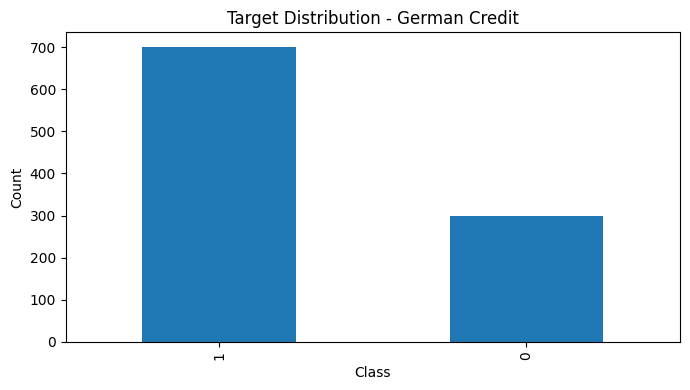

In [9]:
# =========================================================
# 9. Target Variable Inspection
# =========================================================

TARGET_COL = "class"

target_summary = (
    df[TARGET_COL]
    .value_counts(dropna=False)
    .reset_index()
)
target_summary.columns = [TARGET_COL, "count"]
target_summary["percentage"] = target_summary["count"] / len(df) * 100

display(target_summary)

# Plot target distribution
ax = target_summary.plot(kind="bar", x=TARGET_COL, y="count", legend=False, figsize=(7, 4))
ax.set_title("Target Distribution - German Credit")
ax.set_xlabel("Class")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Separate Numeric and Categorical Features

This separation supports numeric summaries, categorical summaries, and later preprocessing decisions.

In [10]:
# =========================================================
# 10. Separate Numeric and Categorical Features
# =========================================================

feature_cols = [col for col in df.columns if col != TARGET_COL]

numeric_cols = df[feature_cols].select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df[feature_cols].select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numeric features ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical features ({len(categorical_cols)}): {categorical_cols}")

Numeric features (5): ['Unnamed: 0', 'Age', 'Job', 'Credit amount', 'Duration']
Categorical features (5): ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']


## 11. Numeric Feature Summary

This section summarises the distribution of numeric variables. These summaries help identify skewness, potential outliers, and scale differences.

In [11]:
# =========================================================
# 11. Numeric Summary Statistics
# =========================================================

if numeric_cols:
    numeric_summary = df[numeric_cols].describe().T
    numeric_summary["missing_pct"] = df[numeric_cols].isna().mean() * 100
    numeric_summary["skewness"] = df[numeric_cols].skew(numeric_only=True)
    display(numeric_summary)
else:
    numeric_summary = pd.DataFrame()
    print("No numeric columns found.")

,count,mean,std,min,25%,50%,75%,max,missing_pct,skewness
Unnamed: 0,1000.0000,499.5000,288.8194,0.0000,249.7500,499.5000,749.2500,999.0000,0.0000,0.0000
Age,1000.0000,35.5460,11.3755,19.0000,27.0000,33.0000,42.0000,75.0000,0.0000,1.0207
Job,1000.0000,1.9040,0.6536,0.0000,2.0000,2.0000,2.0000,3.0000,0.0000,-0.3743
Credit amount,1000.0000,3271.2580,2822.7369,250.0000,1365.5000,2319.5000,3972.2500,18424.0000,0.0000,1.9496
Duration,1000.0000,20.9030,12.0588,4.0000,12.0000,18.0000,24.0000,72.0000,0.0000,1.0942


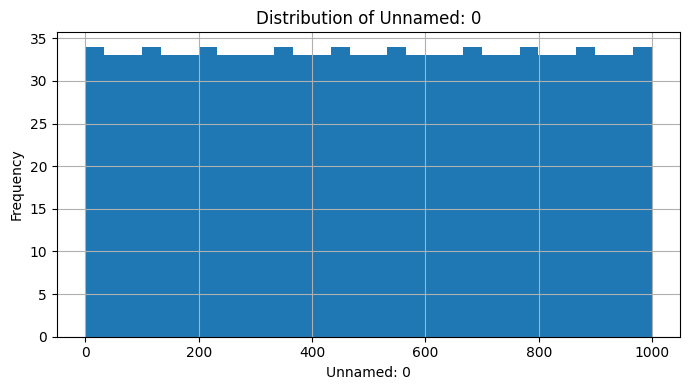

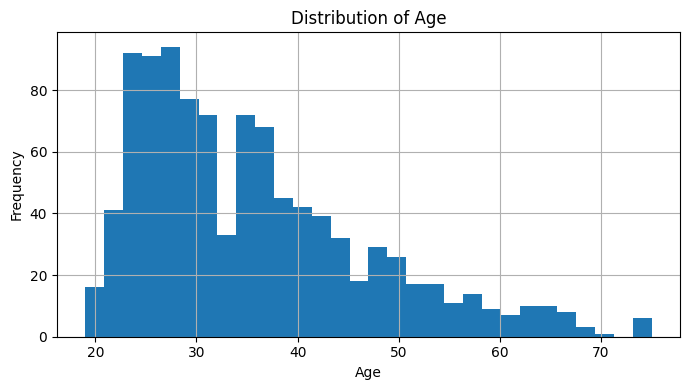

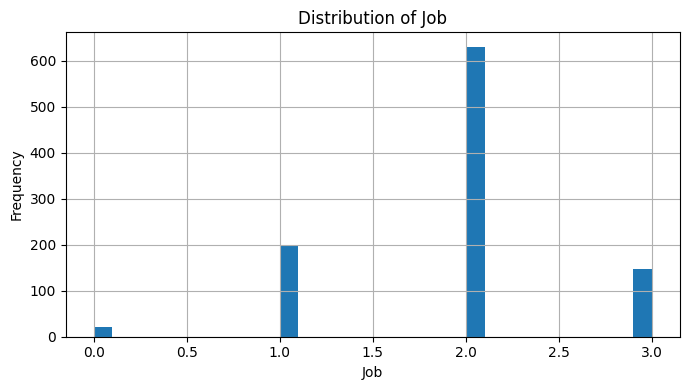

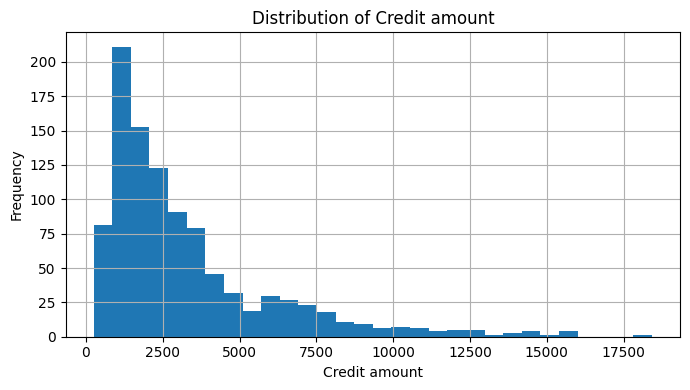

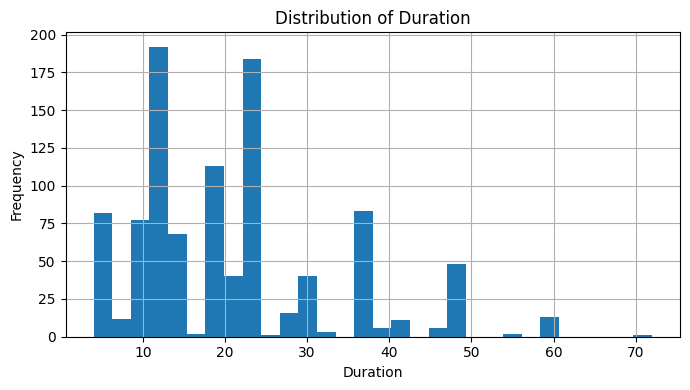

In [12]:
# =========================================================
# 12. Numeric Histograms
# =========================================================

for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    df[col].hist(bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig(FIGURES_PATH / f"hist_{col}.png", dpi=300, bbox_inches="tight")
    plt.show()

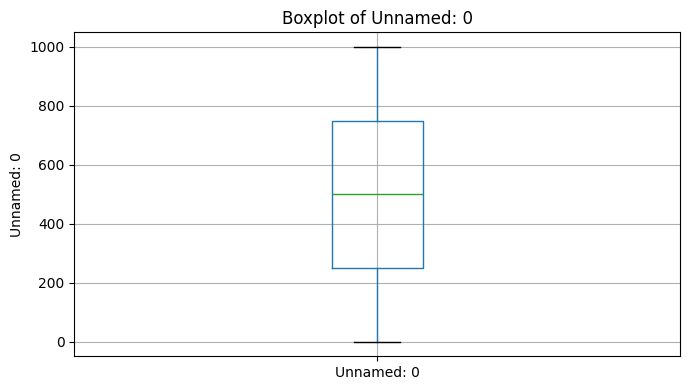

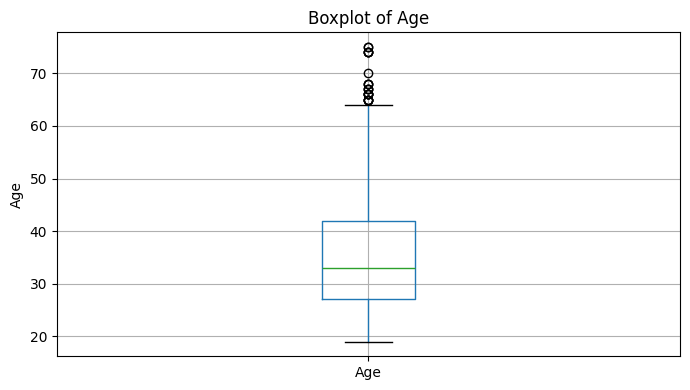

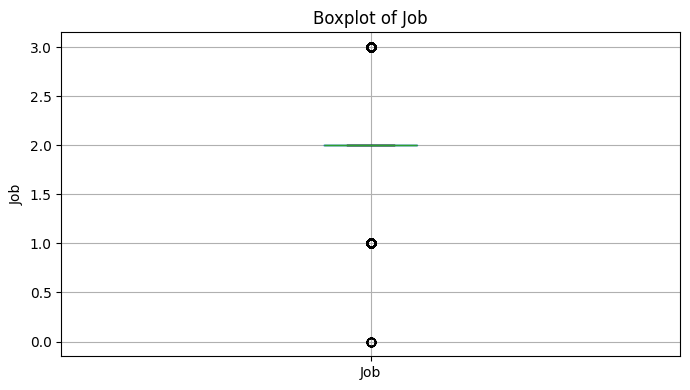

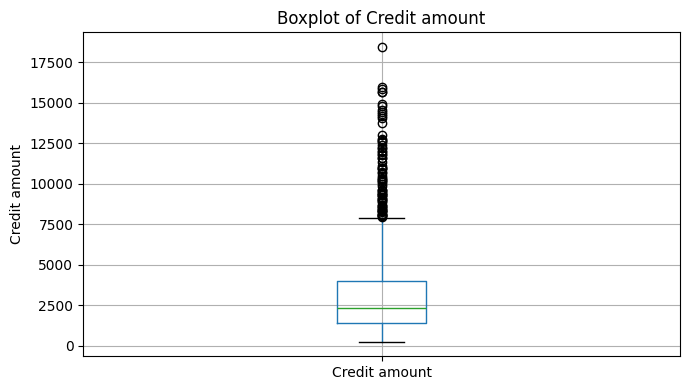

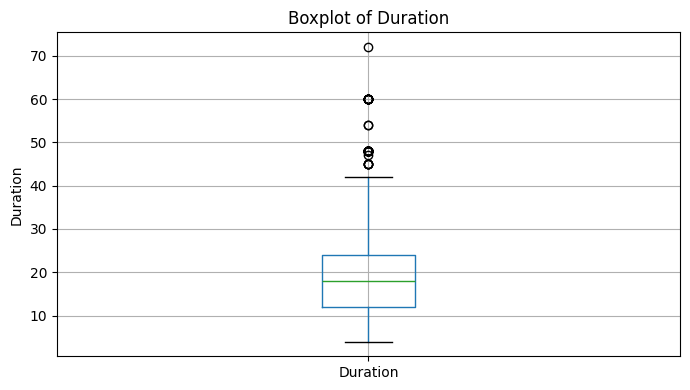

In [13]:
# =========================================================
# 13. Numeric Boxplots for Outlier Inspection
# =========================================================

for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    df.boxplot(column=col)
    plt.title(f"Boxplot of {col}")
    plt.ylabel(col)
    plt.tight_layout()
    plt.savefig(FIGURES_PATH / f"boxplot_{col}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [14]:
# =========================================================
# 14. Outlier Summary using IQR Rule
# =========================================================

outlier_records = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    outlier_pct = outlier_count / len(df) * 100

    if outlier_pct == 0:
        outlier_level = "None"
    elif outlier_pct <= 1:
        outlier_level = "Very low"
    elif outlier_pct <= 5:
        outlier_level = "Mild"
    elif outlier_pct <= 10:
        outlier_level = "Significant"
    else:
        outlier_level = "Heavy"

    outlier_records.append({
        "feature": col,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_pct": outlier_pct,
        "outlier_level": outlier_level
    })

outlier_summary = pd.DataFrame(outlier_records)
display(outlier_summary)

,feature,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_pct,outlier_level
0,Unnamed: 0,249.7500,749.2500,499.5000,-499.5000,1498.5000,0,0.0000,None
1,Age,27.0000,42.0000,15.0000,4.5000,64.5000,23,2.3000,Mild
2,Job,2.0000,2.0000,0.0000,2.0000,2.0000,370,37.0000,Heavy
3,Credit amount,1365.5000,3972.2500,2606.7500,-2544.6250,7882.3750,72,7.2000,Significant
4,Duration,12.0000,24.0000,12.0000,-6.0000,42.0000,70,7.0000,Significant


## 12. Categorical Feature Summary

This section inspects categorical variables, category frequencies, and rare categories. Rare categories may require careful handling during preprocessing.


Categorical distribution: Sex


,Sex,count,percentage
0,male,690,69.0000
1,female,310,31.0000


<Figure size 800x400 with 0 Axes>

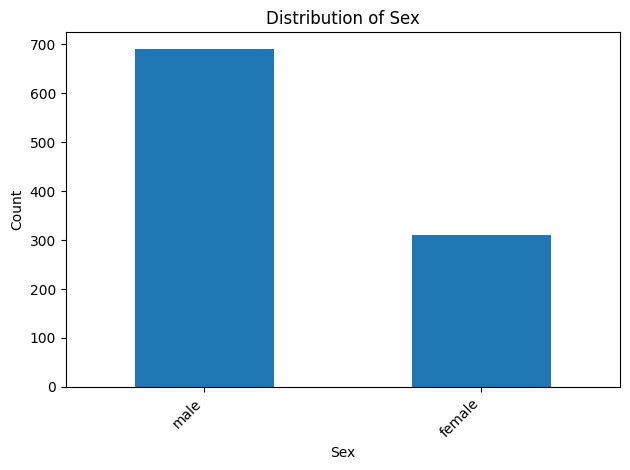


Categorical distribution: Housing


,Housing,count,percentage
0,own,713,71.3000
1,rent,179,17.9000
2,free,108,10.8000


<Figure size 800x400 with 0 Axes>

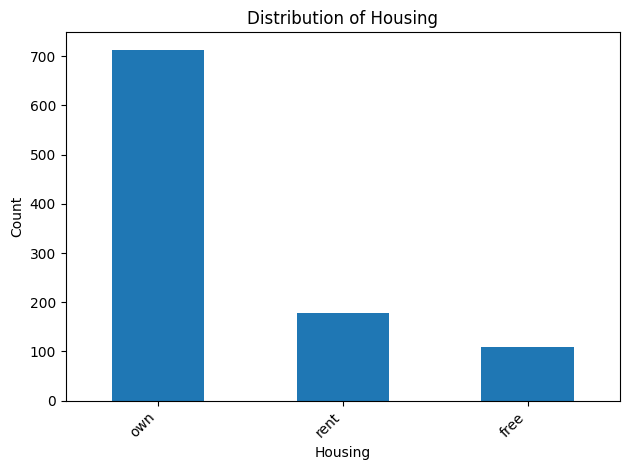


Categorical distribution: Saving accounts


,Saving accounts,count,percentage
0,little,603,60.3000
1,NaN,183,18.3000
2,moderate,103,10.3000
3,quite rich,63,6.3000
4,rich,48,4.8000


<Figure size 800x400 with 0 Axes>

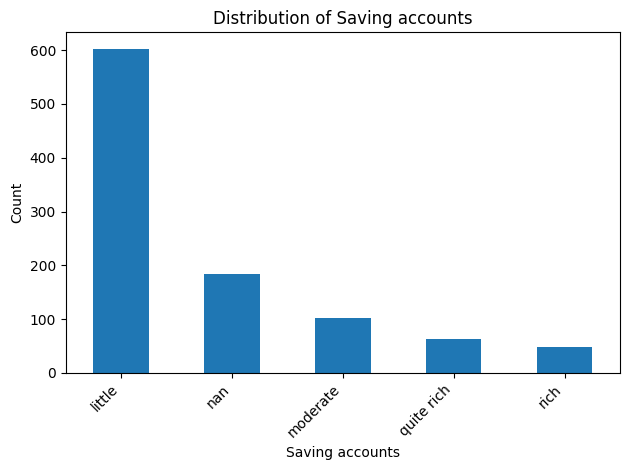


Categorical distribution: Checking account


,Checking account,count,percentage
0,NaN,394,39.4000
1,little,274,27.4000
2,moderate,269,26.9000
3,rich,63,6.3000


<Figure size 800x400 with 0 Axes>

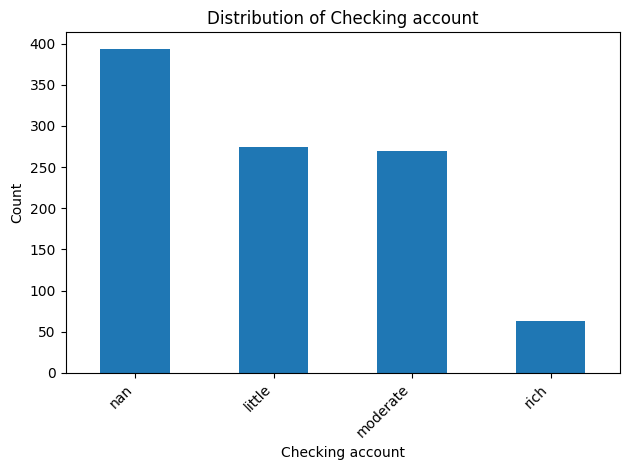


Categorical distribution: Purpose


,Purpose,count,percentage
0,car,337,33.7000
1,radio/TV,280,28.0000
2,furniture/equipment,181,18.1000
3,business,97,9.7000
4,education,59,5.9000
5,repairs,22,2.2000
6,domestic appliances,12,1.2000
7,vacation/others,12,1.2000


<Figure size 800x400 with 0 Axes>

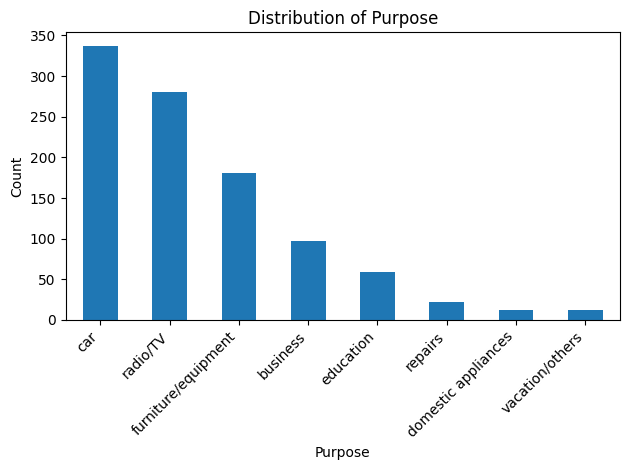

In [15]:
# =========================================================
# 15. Categorical Feature Distributions
# =========================================================

categorical_distribution_tables = {}

for col in categorical_cols:
    category_summary = (
        df[col]
        .value_counts(dropna=False)
        .reset_index()
    )
    category_summary.columns = [col, "count"]
    category_summary["percentage"] = category_summary["count"] / len(df) * 100
    categorical_distribution_tables[col] = category_summary

    print(f"\nCategorical distribution: {col}")
    display(category_summary)

    plt.figure(figsize=(8, 4))
    category_summary.plot(kind="bar", x=col, y="count", legend=False)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(FIGURES_PATH / f"category_distribution_{col}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [16]:
# =========================================================
# 16. Rare Category Check
# =========================================================

RARE_THRESHOLD_PCT = 5
rare_records = []

for col in categorical_cols:
    temp = df[col].value_counts(dropna=False).reset_index()
    temp.columns = ["category", "count"]
    temp["percentage"] = temp["count"] / len(df) * 100
    temp["feature"] = col
    temp["rare_flag"] = temp["percentage"] < RARE_THRESHOLD_PCT
    rare_records.append(temp[["feature", "category", "count", "percentage", "rare_flag"]])

rare_category_summary = pd.concat(rare_records, ignore_index=True) if rare_records else pd.DataFrame()
display(rare_category_summary)

,feature,category,count,percentage,rare_flag
0,Sex,male,690,69.0000,False
1,Sex,female,310,31.0000,False
2,Housing,own,713,71.3000,False
3,Housing,rent,179,17.9000,False
4,Housing,free,108,10.8000,False
5,Saving accounts,little,603,60.3000,False
6,Saving accounts,NaN,183,18.3000,False
7,Saving accounts,moderate,103,10.3000,False
8,Saving accounts,quite rich,63,6.3000,False
9,Saving accounts,rich,48,4.8000,True


## 13. Feature-Target Relationships

This section provides simple exploratory comparisons between features and the target. These are not causal conclusions. They are used only to inform preprocessing and modelling awareness.

,feature,class,count,mean,median,std,min,max
0,Unnamed: 0,0,300,514.7600,541.0000,281.0254,1,998
1,Unnamed: 0,1,700,492.9600,481.5000,292.0497,0,999
2,Age,0,300,33.9633,31.0000,11.2224,19,74
3,Age,1,700,36.2243,34.0000,11.3811,19,75
4,Job,0,300,1.9367,2.0000,0.6689,0,3
5,Job,1,700,1.8900,2.0000,0.6469,0,3
6,Credit amount,0,300,3938.1267,2574.5000,3535.8190,433,18424
7,Credit amount,1,700,2985.4571,2244.0000,2401.4723,250,15857
8,Duration,0,300,24.8600,24.0000,13.2826,6,72
9,Duration,1,700,19.2071,18.0000,11.0796,4,60


<Figure size 700x400 with 0 Axes>

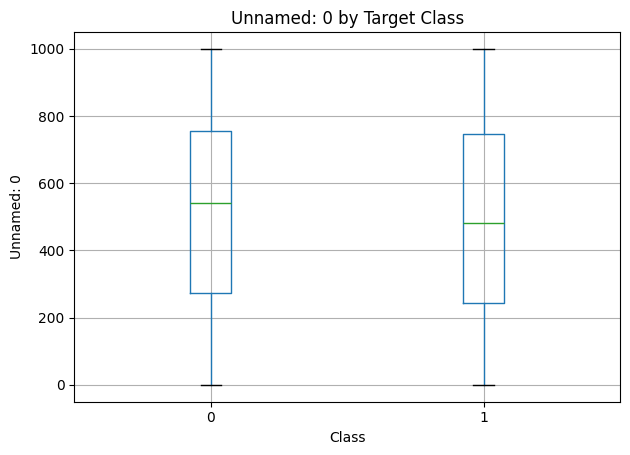

<Figure size 700x400 with 0 Axes>

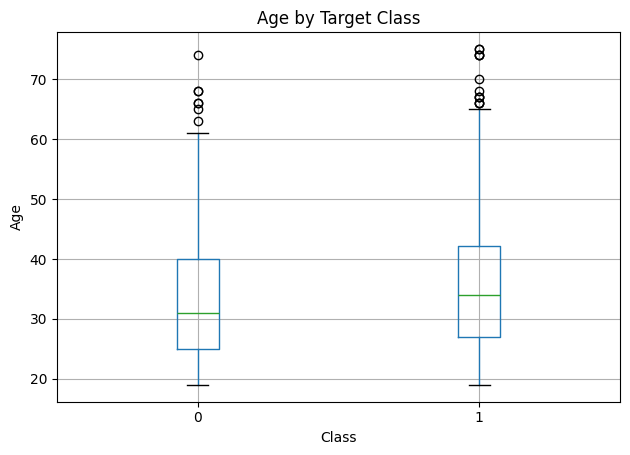

<Figure size 700x400 with 0 Axes>

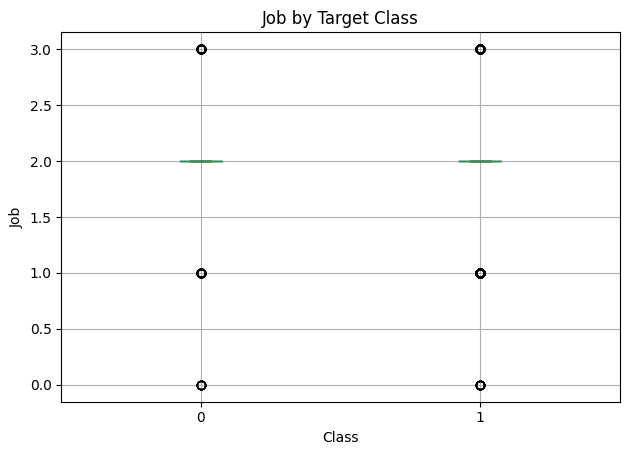

<Figure size 700x400 with 0 Axes>

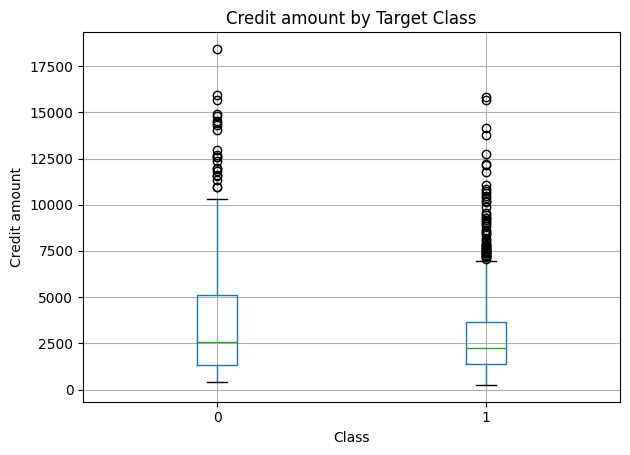

<Figure size 700x400 with 0 Axes>

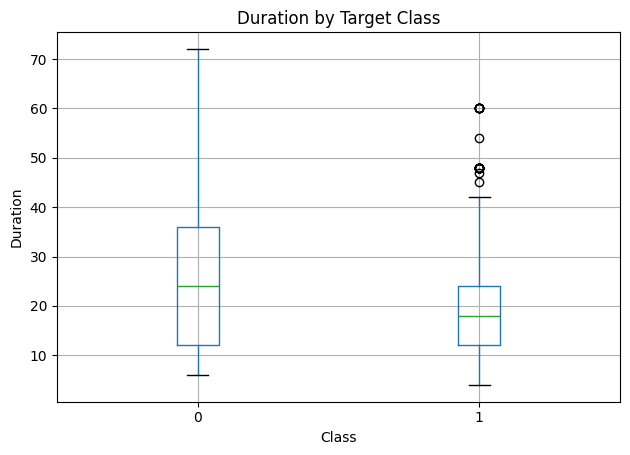

In [17]:
# =========================================================
# 17. Numeric Features vs Target
# =========================================================

numeric_target_summary = []

for col in numeric_cols:
    temp = df.groupby(TARGET_COL)[col].agg(["count", "mean", "median", "std", "min", "max"]).reset_index()
    temp.insert(0, "feature", col)
    numeric_target_summary.append(temp)

numeric_target_summary_df = pd.concat(numeric_target_summary, ignore_index=True) if numeric_target_summary else pd.DataFrame()
display(numeric_target_summary_df)

for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    df.boxplot(column=col, by=TARGET_COL)
    plt.title(f"{col} by Target Class")
    plt.suptitle("")
    plt.xlabel("Class")
    plt.ylabel(col)
    plt.tight_layout()
    plt.savefig(FIGURES_PATH / f"numeric_vs_target_{col}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [18]:
# =========================================================
# 18. Categorical Features vs Target
# =========================================================

categorical_target_tables = {}

for col in categorical_cols:
    crosstab_count = pd.crosstab(df[col], df[TARGET_COL], dropna=False)
    crosstab_pct = pd.crosstab(df[col], df[TARGET_COL], normalize="index", dropna=False) * 100
    categorical_target_tables[col] = {"count": crosstab_count, "percentage": crosstab_pct}

    print(f"\nCategorical feature vs target: {col} - Counts")
    display(crosstab_count)
    print(f"Categorical feature vs target: {col} - Row percentages")
    display(crosstab_pct)


Categorical feature vs target: Sex - Counts


class,0,1
Sex,,
female,109,201
male,191,499


Categorical feature vs target: Sex - Row percentages


class,0,1
Sex,,
female,35.1613,64.8387
male,27.6812,72.3188



Categorical feature vs target: Housing - Counts


...

class,0,1
Checking account,,
little,49.2701,50.7299
moderate,39.0335,60.9665
rich,22.2222,77.7778
NaN,11.6751,88.3249



Categorical feature vs target: Purpose - Counts


class,0,1
Purpose,,
business,34,63
car,106,231
domestic appliances,4,8
education,23,36
furniture/equipment,58,123
radio/TV,62,218
repairs,8,14
vacation/others,5,7


Categorical feature vs target: Purpose - Row percentages


class,0,1
Purpose,,
business,35.0515,64.9485
car,31.4540,68.5460
domestic appliances,33.3333,66.6667
education,38.9831,61.0169
furniture/equipment,32.0442,67.9558
radio/TV,22.1429,77.8571
repairs,36.3636,63.6364
vacation/others,41.6667,58.3333


## 14. Correlation Analysis for Numeric Variables

Correlation is inspected for awareness only. Features are not automatically removed because the objective is to preserve explanatory signal for later explainability analysis.

,Unnamed: 0,Age,Job,Credit amount,Duration
Unnamed: 0,1.0000,-0.0101,-0.0273,0.0135,0.0308
Age,-0.0101,1.0000,0.0157,0.0327,-0.0361
Job,-0.0273,0.0157,1.0000,0.2854,0.2109
Credit amount,0.0135,0.0327,0.2854,1.0000,0.6250
Duration,0.0308,-0.0361,0.2109,0.6250,1.0000


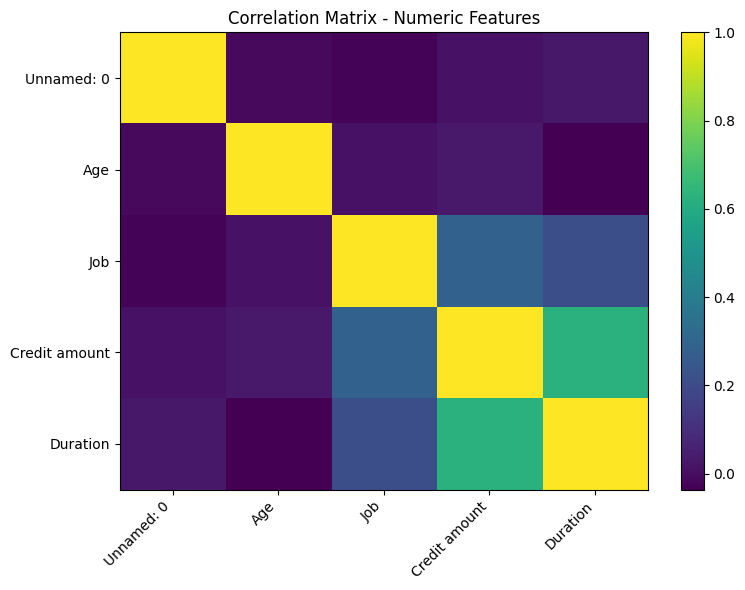

In [19]:
# =========================================================
# 19. Correlation Analysis
# =========================================================

if len(numeric_cols) >= 2:
    corr_matrix = df[numeric_cols].corr()
    display(corr_matrix)

    plt.figure(figsize=(8, 6))
    plt.imshow(corr_matrix, aspect="auto")
    plt.colorbar()
    plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=45, ha="right")
    plt.yticks(range(len(corr_matrix.index)), corr_matrix.index)
    plt.title("Correlation Matrix - Numeric Features")
    plt.tight_layout()
    plt.savefig(FIGURES_PATH / "correlation_matrix_numeric_features.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    corr_matrix = pd.DataFrame()
    print("Not enough numeric columns for correlation analysis.")

In [24]:
# =========================================================
# 20. High Correlation Pair Identification
# =========================================================

HIGH_CORR_THRESHOLD = 0.70
high_corr_records = []

if not corr_matrix.empty:
    for i, col_1 in enumerate(corr_matrix.columns):
        for col_2 in corr_matrix.columns[i+1:]:
            corr_value = corr_matrix.loc[col_1, col_2]
            if abs(corr_value) >= HIGH_CORR_THRESHOLD:
                high_corr_records.append({
                    "feature_1": col_1,
                    "feature_2": col_2,
                    "correlation": corr_value,
                    "absolute_correlation": abs(corr_value)
                })

high_corr_pairs = pd.DataFrame(high_corr_records)
display(high_corr_pairs)

""


## 15. Sensitive Attribute and Proxy Risk Inspection

This section documents sensitive or potentially sensitive variables for later fairness, ethics, and regulatory-alignment analysis.

For German Credit, `Sex` and `Age` are treated as sensitive or potentially sensitive attributes. Some other variables may act as proxies depending on the context.

In [20]:
# =========================================================
# 21. Sensitive Attribute Inspection
# =========================================================

sensitive_features = [col for col in ["Sex", "Age"] if col in df.columns]

sensitive_summary_records = []

for col in sensitive_features:
    if col in categorical_cols:
        temp = df[col].value_counts(dropna=False).reset_index()
        temp.columns = ["value", "count"]
        temp["percentage"] = temp["count"] / len(df) * 100
        temp.insert(0, "feature", col)
        sensitive_summary_records.append(temp)
    else:
        temp = df[col].describe().reset_index()
        temp.columns = ["statistic", "value"]
        temp.insert(0, "feature", col)
        sensitive_summary_records.append(temp)

sensitive_summary = pd.concat(sensitive_summary_records, ignore_index=True) if sensitive_summary_records else pd.DataFrame()
display(sensitive_summary)

,feature,value,count,percentage,statistic
0,Sex,male,690.0000,69.0000,NaN
1,Sex,female,310.0000,31.0000,NaN
2,Age,1000.0000,NaN,NaN,count
3,Age,35.5460,NaN,NaN,mean
4,Age,11.3755,NaN,NaN,std
5,Age,19.0000,NaN,NaN,min
6,Age,27.0000,NaN,NaN,25%
7,Age,33.0000,NaN,NaN,50%
8,Age,42.0000,NaN,NaN,75%
9,Age,75.0000,NaN,NaN,max


## 16. Feature Audit Table

The feature audit table provides a structured record of each variable. This supports transparent preprocessing and later dissertation write-up.

In [25]:
# =========================================================
# 22. Create Feature Audit Table
# =========================================================

def classify_proxy_risk(feature_name):
    feature_lower = feature_name.lower()
    if feature_lower in ["sex", "gender", "race", "age"]:
        return "Sensitive attribute"
    if feature_lower in ["housing", "job", "purpose", "saving accounts", "checking account"]:
        return "Potential socioeconomic proxy"
    return "Low / context-dependent"

feature_audit_records = []

for col in df.columns:
    series = df[col]
    is_target = col == TARGET_COL
    data_type = str(series.dtype)
    missing_pct = series.isna().mean() * 100
    unique_values = series.nunique(dropna=False)

    if col in numeric_cols:
        feature_content = (
            f"min={series.min():.4f}, median={series.median():.4f}, max={series.max():.4f}"
        )
        skewness = series.skew()
        outlier_row = outlier_summary[outlier_summary["feature"] == col]
        outliers_pct = float(outlier_row["outlier_pct"].iloc[0]) if not outlier_row.empty else np.nan
        scaling_note = "To be assessed in preprocessing; RobustScaler likely appropriate if outliers/skewness exist"
        encoding_note = "Not applicable"
    else:
        values = series.dropna().unique().tolist()
        feature_content = ", ".join(map(str, values[:20]))
        if len(values) > 20:
            feature_content += ", ..."
        skewness = np.nan
        outliers_pct = np.nan
        scaling_note = "Not applicable"
        encoding_note = "To be one-hot encoded if used for modelling"

    feature_audit_records.append({
        "feature": col,
        "role": "Target" if is_target else "Input feature",
        "feature_description": "To be documented based on dataset dictionary / domain meaning",
        "feature_content": feature_content,
        "data_type": data_type,
        "sensitive": "Yes" if col in sensitive_features else "No",
        "mutable": "No" if col in ["Age", "Sex", TARGET_COL] else "To be assessed",
        "missing_pct": missing_pct,
        "outliers_pct": outliers_pct,
        "unique_values": unique_values,
        "skewness": skewness,
        "scaling_applied": scaling_note,
        "encoding_applied": encoding_note,
        "imputation_method": "To be defined in preprocessing notebook",
        "proxy_risk": classify_proxy_risk(col),
        "notes": "EDA-stage audit only; final treatment defined in preprocessing notebook"
    })

feature_audit_table = pd.DataFrame(feature_audit_records)
display(feature_audit_table)

,feature,role,feature_description,feature_content,data_type,sensitive,mutable,missing_pct,outliers_pct,unique_values,skewness,scaling_applied,encoding_applied,imputation_method,proxy_risk,notes
0,Unnamed: 0,Input feature,To be documented based on dataset dictionary /...,"min=0.0000, median=499.5000, max=999.0000",int64,No,To be assessed,0.0000,0.0000,1000,0.0000,To be assessed in preprocessing; RobustScaler ...,Not applicable,To be defined in preprocessing notebook,Low / context-dependent,EDA-stage audit only; final treatment defined ...
1,Age,Input feature,To be documented based on dataset dictionary /...,"min=19.0000, median=33.0000, max=75.0000",int64,Yes,No,0.0000,2.3000,53,1.0207,To be assessed in preprocessing; RobustScaler ...,Not applicable,To be defined in preprocessing notebook,Sensitive attribute,EDA-stage audit only; final treatment defined ...
2,Sex,Input feature,To be documented based on dataset dictionary /...,"male, female",object,Yes,No,0.0000,NaN,2,NaN,Not applicable,To be one-hot encoded if used for modelling,To be defined in preprocessing notebook,Sensitive attribute,EDA-stage audit only; final treatment defined ...
3,Job,Input feature,To be documented based on dataset dictionary /...,"min=0.0000, median=2.0000, max=3.0000",int64,No,To be assessed,0.0000,37.0000,4,-0.3743,To be assessed in preprocessing; RobustScaler ...,Not applicable,To be defined in preprocessing notebook,Potential socioeconomic proxy,EDA-stage audit only; final treatment defined ...
4,Housing,Input feature,To be documented based on dataset dictionary /...,"own, free, rent",object,No,To be assessed,0.0000,NaN,3,NaN,Not applicable,To be one-hot encoded if used for modelling,To be defined in preprocessing notebook,Potential socioeconomic proxy,EDA-stage audit only; final treatment defined ...
5,Saving accounts,Input feature,To be documented based on dataset dictionary /...,"little, quite rich, rich, moderate",object,No,To be assessed,18.3000,NaN,5,NaN,Not applicable,To be one-hot encoded if used for modelling,To be defined in preprocessing notebook,Potential socioeconomic proxy,EDA-stage audit only; final treatment defined ...
6,Checking account,Input feature,To be documented based on dataset dictionary /...,"little, moderate, rich",object,No,To be assessed,39.4000,NaN,4,NaN,Not applicable,To be one-hot encoded if used for modelling,To be defined in preprocessing notebook,Potential socioeconomic proxy,EDA-stage audit only; final treatment defined ...
7,Credit amount,Input feature,To be documented based on dataset dictionary /...,"min=250.0000, median=2319.5000, max=18424.0000",int64,No,To be assessed,0.0000,7.2000,921,1.9496,To be assessed in preprocessing; RobustScaler ...,Not applicable,To be defined in preprocessing notebook,Low / context-dependent,EDA-stage audit only; final treatment defined ...
8,Duration,Input feature,To be documented based on dataset dictionary /...,"min=4.0000, median=18.0000, max=72.0000",int64,No,To be assessed,0.0000,7.0000,33,1.0942,To be assessed in preprocessing; RobustScaler ...,Not applicable,To be defined in preprocessing notebook,Low / context-dependent,EDA-stage audit only; final treatment defined ...
9,Purpose,Input feature,To be documented based on dataset dictionary /...,"radio/TV, education, furniture/equipment, car,...",object,No,To be assessed,0.0000,NaN,8,NaN,Not applicable,To be one-hot encoded if used for modelling,To be defined in preprocessing notebook,Potential socioeconomic proxy,EDA-stage audit only; final treatment defined ...


## 17. Compact EDA Summary

This section creates a compact summary of the EDA findings. It is useful for dissertation documentation and supervisor review.

In [26]:
# =========================================================
# 23. Compact EDA Summary
# =========================================================

eda_summary = pd.DataFrame({
    "metric": [
        "dataset_name",
        "rows",
        "columns",
        "input_features",
        "numeric_features",
        "categorical_features",
        "duplicate_rows",
        "features_with_missing_values",
        "target_column",
        "target_classes",
        "sensitive_features_documented"
    ],
    "value": [
        DATASET_NAME,
        df.shape[0],
        df.shape[1],
        len(feature_cols),
        len(numeric_cols),
        len(categorical_cols),
        duplicate_count,
        int((missing_summary["missing_count"] > 0).sum()),
        TARGET_COL,
        df[TARGET_COL].nunique(dropna=False),
        ", ".join(sensitive_features) if sensitive_features else "None identified"
    ]
})

display(eda_summary)

,metric,value
0,dataset_name,german_credit
1,rows,1000
2,columns,11
3,input_features,10
4,numeric_features,5
5,categorical_features,5
6,duplicate_rows,0
7,features_with_missing_values,2
8,target_column,class
9,target_classes,2


## 18. Save EDA Outputs

All outputs are saved into the standard result folder for this notebook.

In [27]:
# =========================================================
# 24. Save EDA Outputs
# =========================================================

excel_output_path = TABLES_PATH / "manual_eda_german_credit_outputs.xlsx"
clean_dataset_output_path = DATASETS_PATH / "german_credit_with_target.csv"

# Save combined dataset with target
df.to_csv(clean_dataset_output_path, index=False)

with pd.ExcelWriter(excel_output_path, engine="openpyxl") as writer:
    eda_summary.to_excel(writer, sheet_name="eda_summary", index=False)
    missing_summary.to_excel(writer, sheet_name="missing_summary", index=False)
    unique_summary.to_excel(writer, sheet_name="unique_summary", index=False)
    target_summary.to_excel(writer, sheet_name="target_summary", index=False)
    feature_audit_table.to_excel(writer, sheet_name="feature_audit_table", index=False)

    if not numeric_summary.empty:
        numeric_summary.to_excel(writer, sheet_name="numeric_summary")
    if not outlier_summary.empty:
        outlier_summary.to_excel(writer, sheet_name="outlier_summary", index=False)
    if not rare_category_summary.empty:
        rare_category_summary.to_excel(writer, sheet_name="rare_categories", index=False)
    if not numeric_target_summary_df.empty:
        numeric_target_summary_df.to_excel(writer, sheet_name="numeric_vs_target", index=False)
    if not high_corr_pairs.empty:
        high_corr_pairs.to_excel(writer, sheet_name="high_corr_pairs", index=False)

print("EDA outputs saved successfully.")
print(f"Excel output: {excel_output_path}")
print(f"Combined dataset output: {clean_dataset_output_path}")
print(f"Figures folder: {FIGURES_PATH}")

EDA outputs saved successfully.
Excel output: /content/drive/MyDrive/Master_Research/07_Results/german_credit/01_manual_eda_german_credit/tables/manual_eda_german_credit_outputs.xlsx
Combined dataset output: /content/drive/MyDrive/Master_Research/07_Results/german_credit/01_manual_eda_german_credit/datasets/german_credit_with_target.csv
Figures folder: /content/drive/MyDrive/Master_Research/07_Results/german_credit/01_manual_eda_german_credit/figures


## 19. EDA Findings and Preprocessing Implications

The findings from this notebook should be used in the next notebook:

`02_data_preprocessing_german_credit.ipynb`

### Expected preprocessing implications

1. Categorical variables should be encoded consistently, most likely using one-hot encoding.
2. Numeric variables should be scaled after train-test splitting to avoid data leakage.
3. Missing values should be handled explicitly.
4. Outliers should not be automatically removed unless there is a defensible data-quality reason.
5. Sensitive variables should be documented for later fairness and ethics analysis.
6. The final preprocessing pipeline should preserve reproducibility and support model comparison across Logistic Regression, Decision Tree, Random Forest, XGBoost, and MLP.

### Link to EES Framework

This notebook does not calculate EES metrics directly. However, it supports the EES framework by documenting the dataset context, feature characteristics, target structure, and potential ethical considerations before modelling begins.

## 20. Extension Notes for Recidivism and Diabetes

To extend this notebook to another dataset, update only:

```python
DATASET_NAME = "recidivism"
NOTEBOOK_NAME = "01_manual_eda_recidivism"
RAW_DATA_PATH = ROOT_PATH / "03_Data" / "01_Raw_Data" / DATASET_NAME / "<file_name>.csv"
TARGET_COL = "<target_column>"
```

The same EDA structure should be retained so that all datasets are analysed consistently.